MONTE CARLO BER SIMULATION

Modulation: BPSK
Eb/N0 =  0 dB | Errors =  826 | Bits =    10000 | BER = 8.2600e-02
Eb/N0 =  2 dB | Errors =  406 | Bits =    10000 | BER = 4.0600e-02
Eb/N0 =  4 dB | Errors =  261 | Bits =    20000 | BER = 1.3050e-02
Eb/N0 =  6 dB | Errors =  213 | Bits =   100000 | BER = 2.1300e-03
Eb/N0 =  8 dB | Errors =  191 | Bits =  1000000 | BER = 1.9100e-04
Eb/N0 = 10 dB | Errors =    3 | Bits =  1000000 | BER = 3.0000e-06
Eb/N0 = 12 dB | Errors =    0 | Bits =  1000000 | BER = 3.0000e-06
Eb/N0 = 14 dB | Errors =    0 | Bits =  1000000 | BER = 3.0000e-06
Eb/N0 = 16 dB | Errors =    0 | Bits =  1000000 | BER = 3.0000e-06
Eb/N0 = 18 dB | Errors =    0 | Bits =  1000000 | BER = 3.0000e-06
Eb/N0 = 20 dB | Errors =    0 | Bits =  1000000 | BER = 3.0000e-06

Modulation: QPSK
Eb/N0 =  0 dB | Errors = 1094 | Bits =    10000 | BER = 1.0940e-01
Eb/N0 =  2 dB | Errors =  653 | Bits =    10000 | BER = 6.5300e-02
Eb/N0 =  4 dB | Errors =  339 | Bits =    20000 | BER = 1.6950e-02

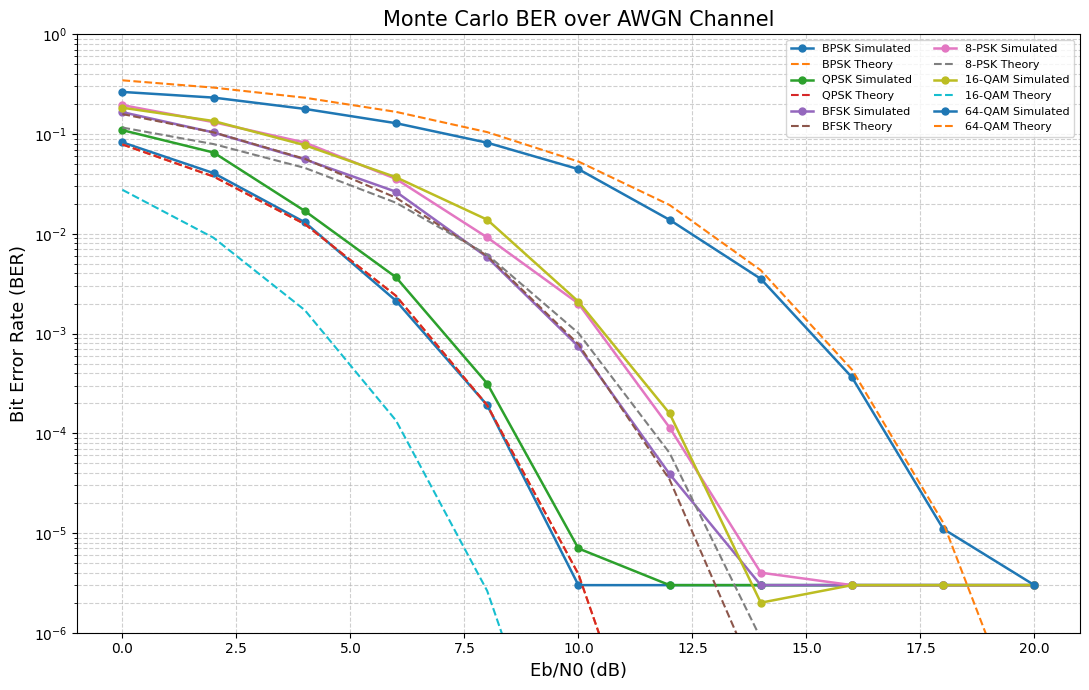

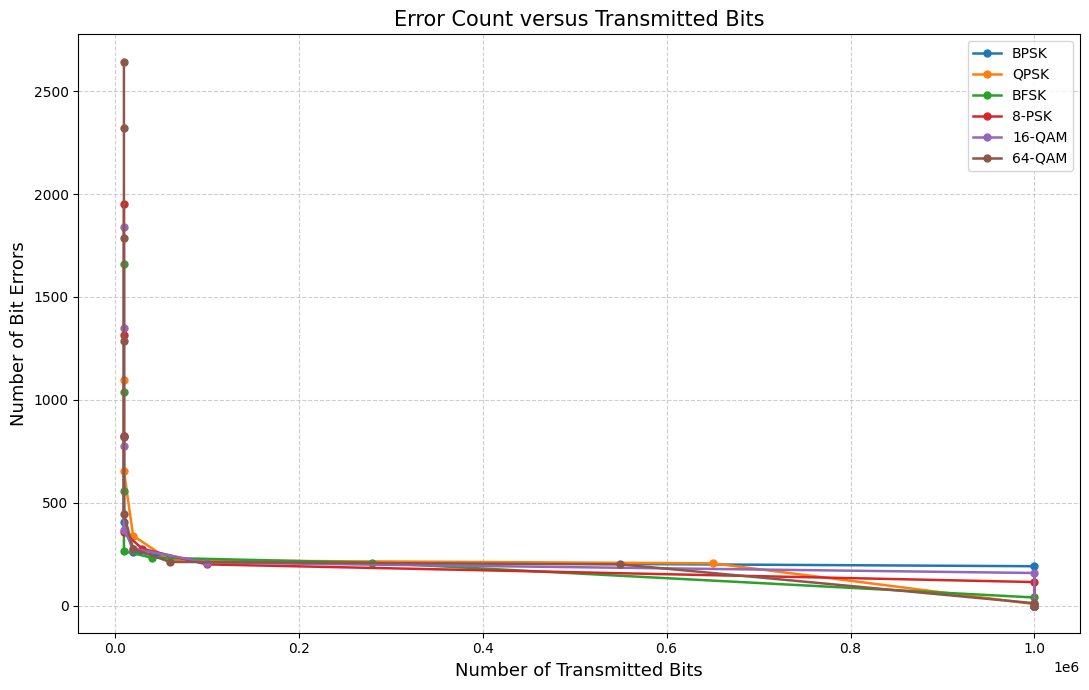


FINAL BER RESULTS
Modulation   Eb/N0    Errors     Bits         BER           
BPSK         0        826        10000        8.2600e-02
BPSK         2        406        10000        4.0600e-02
BPSK         4        261        20000        1.3050e-02
BPSK         6        213        100000       2.1300e-03
BPSK         8        191        1000000      1.9100e-04
BPSK         10       3          1000000      3.0000e-06
BPSK         12       0          1000000      3.0000e-06
BPSK         14       0          1000000      3.0000e-06
BPSK         16       0          1000000      3.0000e-06
BPSK         18       0          1000000      3.0000e-06
BPSK         20       0          1000000      3.0000e-06
QPSK         0        1094       10000        1.0940e-01
QPSK         2        653        10000        6.5300e-02
QPSK         4        339        20000        1.6950e-02
QPSK         6        220        60000        3.6667e-03
QPSK         8        205        650000       3.1538e-04
QPSK    

In [ ]:
# ================================================================
# EXPERIMENT 12: MONTE CARLO BER OVER AWGN
# BPSK, QPSK, BFSK, 8-PSK, 16-QAM and 64-QAM
# ================================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc, erfc as Q_erfc
from scipy.special import ndtr
from math import log2, sqrt
import warnings
warnings.filterwarnings("ignore")

# -------------------- PARAMETERS --------------------

EbN0_dB = np.arange(0, 21, 2)
MAX_BITS = 10**6
TARGET_ERRORS = 200
rng = np.random.default_rng(42)

modulations = ["BPSK", "QPSK", "BFSK", "8-PSK", "16-QAM", "64-QAM"]

# Results storage
BER_sim = {m: [] for m in modulations}
BER_theory = {m: [] for m in modulations}
error_counts = {m: [] for m in modulations}
bit_counts = {m: [] for m in modulations}

# -------------------- CONSTELLATIONS --------------------

def constellation(mod):
    if mod == "BPSK":
        return np.array([-1+0j, 1+0j])

    if mod == "QPSK":
        return np.exp(1j * (np.pi/4 + np.arange(4)*np.pi/2))

    if mod == "BFSK":
        return np.array([[1,0], [0,1]], dtype=complex)

    if mod == "8-PSK":
        return np.exp(1j * 2*np.pi*np.arange(8)/8)

    if mod == "16-QAM":
        levels = np.array([-3,-1,1,3])
        return np.array([x+1j*y for y in levels for x in levels]) / np.sqrt(10)

    if mod == "64-QAM":
        levels = np.array([-7,-5,-3,-1,1,3,5,7])
        return np.array([x+1j*y for y in levels for x in levels]) / np.sqrt(42)

# -------------------- THEORY --------------------

def theoretical_ber(mod, ebno):
    gamma = 10**(ebno/10)

    if mod in ["BPSK", "QPSK"]:
        return 0.5 * erfc(np.sqrt(gamma))

    if mod == "BFSK":
        return 0.5 * erfc(np.sqrt(gamma/2))

    if mod == "8-PSK":
        k = 3
        return min(0.5, (1/k) * erfc(
            np.sqrt(k*gamma) * np.sin(np.pi/8)
        ))

    if mod == "16-QAM":
        k = 4
        return (3/(2*k)) * erfc(
            np.sqrt((4/5)*k*gamma/2)
        )

    if mod == "64-QAM":
        k = 6
        return (4/k)*(1-1/8) * 0.5 * erfc(
            np.sqrt((3*k*gamma)/(2*63))
        ) * 2

# -------------------- BIT CONVERSION --------------------

def bits_to_symbols(bits, mod):
    k = int(log2(len(constellation(mod))))
    groups = bits.reshape(-1, k)
    weights = 2**np.arange(k-1, -1, -1)
    return groups @ weights

def symbols_to_bits(indices, mod):
    k = int(log2(len(constellation(mod))))
    return ((indices[:, None] >> np.arange(k-1, -1, -1)) & 1).astype(int)

# -------------------- MODULATION --------------------

def modulate(indices, mod):
    c = constellation(mod)
    return c[indices]

# -------------------- AWGN CHANNEL --------------------

def add_noise(tx, mod, ebno):
    k = int(log2(len(constellation(mod))))
    Eb = 1/k

    # Complex noise variance = N0
    N0 = Eb / (10**(ebno/10))

    if mod == "BFSK":
        noise = np.sqrt(N0/2) * (
            rng.normal(size=tx.shape) +
            1j*rng.normal(size=tx.shape)
        )
    else:
        noise = np.sqrt(N0/2) * (
            rng.normal(size=tx.shape) +
            1j*rng.normal(size=tx.shape)
        )

    return tx + noise

# -------------------- MINIMUM DISTANCE DETECTOR --------------------

def detect(rx, mod):
    c = constellation(mod)

    if mod == "BFSK":
        distances = np.sum(
            np.abs(rx[:, None, :] - c[None, :, :])**2, axis=2
        )
    else:
        distances = np.abs(rx[:, None] - c[None, :])**2

    return np.argmin(distances, axis=1)

# -------------------- MONTE CARLO SIMULATION --------------------

print("="*65)
print("MONTE CARLO BER SIMULATION")
print("="*65)

for mod in modulations:
    print("\nModulation:", mod)

    k = int(log2(len(constellation(mod))))

    for ebno in EbN0_dB:
        errors = 0
        total_bits = 0

        while errors < TARGET_ERRORS and total_bits < MAX_BITS:

            remaining = MAX_BITS - total_bits
            batch_bits = min(10000, remaining)
            batch_bits = (batch_bits // k) * k

            if batch_bits == 0:
                break

            bits = rng.integers(0, 2, batch_bits)

            indices = bits_to_symbols(bits, mod)
            tx = modulate(indices, mod)

            if mod == "BFSK":
                # Orthogonal BFSK: each signal has unit energy
                rx = add_noise(tx, mod, ebno)
            else:
                rx = add_noise(tx, mod, ebno)

            detected = detect(rx, mod)
            recovered = symbols_to_bits(detected, mod)

            batch_errors = np.sum(bits != recovered.flatten())

            errors += batch_errors
            total_bits += batch_bits

        # BER estimate and zero-error upper bound
        if errors == 0:
            ber = 3/total_bits
        else:
            ber = errors/total_bits

        BER_sim[mod].append(ber)
        BER_theory[mod].append(theoretical_ber(mod, ebno))
        error_counts[mod].append(errors)
        bit_counts[mod].append(total_bits)

        print(f"Eb/N0 = {ebno:2d} dB | Errors = {errors:4d} | "
              f"Bits = {total_bits:8d} | BER = {ber:.4e}")

# -------------------- VALIDATION TESTS --------------------

print("\n" + "="*65)
print("MANDATORY VALIDATION")
print("="*65)

for mod in modulations:
    k = int(log2(len(constellation(mod))))
    # Make sure test_bits is a multiple of k
    num_test_bits = (10000 // k) * k
    test_bits = rng.integers(0, 2, num_test_bits)
    test_indices = bits_to_symbols(test_bits, mod)
    test_tx = modulate(test_indices, mod)

    detected = detect(test_tx, mod)
    recovered = symbols_to_bits(detected, mod)

    noiseless_errors = np.sum(test_bits != recovered.flatten())

    print(f"{mod}: Noiseless errors = {noiseless_errors}")

    assert noiseless_errors == 0, "Noiseless detection failed!"

print("Noiseless validation PASSED!")

# -------------------- BER CURVES --------------------

plt.figure(figsize=(11, 7))

for mod in modulations:
    plt.semilogy(EbN0_dB, BER_sim[mod], 'o-',
                 linewidth=1.8, markersize=5, label=mod + " Simulated")
    plt.semilogy(EbN0_dB, BER_theory[mod], '--',
                 linewidth=1.5, label=mod + " Theory")

plt.xlabel("Eb/N0 (dB)", fontsize=13)
plt.ylabel("Bit Error Rate (BER)", fontsize=13)
plt.title("Monte Carlo BER over AWGN Channel", fontsize=15)
plt.grid(True, which="both", linestyle="--", alpha=0.6)
plt.legend(fontsize=8, ncol=2)
plt.ylim(1e-6, 1)
plt.tight_layout()
plt.show()

# -------------------- ERROR COUNT VS BITS --------------------

plt.figure(figsize=(11, 7))

for mod in modulations:
    plt.plot(bit_counts[mod], error_counts[mod], 'o-',
             linewidth=1.8, markersize=5, label=mod)

plt.xlabel("Number of Transmitted Bits", fontsize=13)
plt.ylabel("Number of Bit Errors", fontsize=13)
plt.title("Error Count versus Transmitted Bits", fontsize=15)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# -------------------- FINAL RESULTS TABLE --------------------

print("\n" + "="*75)
print("FINAL BER RESULTS")
print("="*75)

print(f"{'Modulation':<12} {'Eb/N0':<8} {'Errors':<10} "
      f"{'Bits':<12} {'BER':<14}")

for mod in modulations:
    for i, ebno in enumerate(EbN0_dB):
        print(f"{mod:<12} {ebno:<8} "
              f"{error_counts[mod][i]:<10} "
              f"{bit_counts[mod][i]:<12} "
              f"{BER_sim[mod][i]:.4e}")

print("\nEXPERIMENT 12 COMPLETED SUCCESSFULLY!")